#Loan Approval Prediction: A Machine Learning & Risk Analysis Case Study

## Project Overview

This project explored the use of machine learning to predict loan approval outcomes by using applicant characteristics, financial information, credit history, and loan details.

The dataset used contained applicant information such as income, employment experience, credit score, requested loan amount, loan purpose, and previous loan default data. The target variable, loan_status, indicated whether an application was approved (1) or not approved (0).

The goal was to build and evaluate classification models that identify patterns associated with historical loan approval decisions. This project compared Logistic Regression, Random Forest, and Gradient Boosting models.

### Business Questions



* Which applicant and loan characteristics are associated with historical approval outcomes?

* How well can different machine learning models distinguish approved from non-approved applications?

* How do classification thresholds affect precision, recall, and predicted approval rates?

* How reliable are the models' predicted probabilities?

* Do model performance metrics differ across different demographic groups?

### Methodology

The analysis included data quality checks, exploratory data analysis, feature selection, preprocessing, model training, performance comparison, threshold analysis, model interpretation, and a preliminary subgroup fairness audit.

### Important Limitations

The target represented historical approval outcomes, not whether a borrower repaid a loan. Predicting historical decisions is not the same as predicting future default risk.



##IMPORT LIBRARIES AND SET UP ENVIRONMENT

Python libraries were imported and used throughout this project.

* NumPy can support numerical calculations and array operations

* Pandas can be used to load, clean, transform, and summarize tabular data

* Matplotlib can be used to create visualizations for exploratory data analysis and model evaluation

* Scikit-learn can provide tools for splitting data, preprocessing features, training classifiers, and measuring model performance

* IPython display can improve presentation of dataframes

A fixed random seed (RANDOM_STATE=42) was used to randomize steps, such as the train-test split and model initialization. This was used to make results reproducible under the same environment and data.

Pandas display settings allowed wider tables to be inspected more easily.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score, accuracy_score, brier_score_loss,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve
from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Setup complete.")

Setup complete.


The dataset was loaded from a CSV file into a Pandas DataFrame. The basic structure fo the data was checked before cleaning or transformations were performed.

The first five records were printed to show a preview of the dataset, its variables and its formats. The dataset's dimensions showed the number of observations and different features and the column list displayed the different variables.

This step was important because it can inform future stages of the analysis.

In [ ]:
import pandas as pd

df_raw = pd.read_csv("loan_data.csv")

display(df_raw.head())

print(f"Number of rows: {df_raw.shape[0]:,}")
print(f"Number of columns: {df_raw.shape[1]:,}")

print("\nColumn names:")
print(df_raw.columns.tolist())

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


Number of rows: 45,000
Number of columns: 14

Column names:
['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'loan_status']


Column names were standardized by removing leading and trailing spaces, converting text to lowercase, and replacing spaces or special characters with underscores. This was done to make things easier to check in Python.

The code checked that both outcome classes of the target variable (whether loan_status was approved (1) or denied (0)) were present in the dataset. Historical approval rate was also calculated.

The target variable was later used to train binary classification model.

In [ ]:
df = df_raw.copy()
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)

TARGET = "loan_status"
if TARGET not in df.columns:
    raise ValueError(
        f"Expected target '{TARGET}' was not found. Available columns: {df.columns.tolist()}"
    )

print("Target values and counts:")
display(df[TARGET].value_counts(dropna=False).rename("count").to_frame())


df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)

if df[TARGET].nunique() != 2:
    raise ValueError("The target must contain both 0 and 1 after cleaning.")

print(f"Rows with a valid binary target: {len(df):,}")
print(f"Historical approval rate: {df[TARGET].mean():.1%}")

Target values and counts:


,count
loan_status,
0,35000
1,10000


Rows with a valid binary target: 45,000
Historical approval rate: 22.2%


## Data Quality Assessment and Cleaning

Before performing exploratory analysis or training models, the dataset was examined for possible issues with data quality.

The assessment included:

* duplicate record detection
* inspection of variable data types
* counts and percentages of missing values
* summary statistics for numeric variables
* checks for potentially unrealistic values (e.g. 500 years of experience)

Potentially questionable observations can be flagged for review rather than automatically assumed to be errors. Exact duplicate rows can be removed.

Cleaning decisions can affect conclusions and model performance.

In [ ]:
print("Duplicate rows:", int(df.duplicated().sum()))
print("\\nData types:")
display(df.dtypes.rename("dtype").to_frame())

missing = (
    df.isna().sum().to_frame("missing_count")
      .assign(missing_pct=lambda x: 100 * x["missing_count"] / len(df))
      .sort_values("missing_pct", ascending=False)
)
display(missing)

print("Numeric summary:")
display(df.describe(include=[np.number]).T)


if "person_age" in df.columns:
    df["flag_age_over_100"] = pd.to_numeric(df["person_age"], errors="coerce") > 100
if "person_emp_exp" in df.columns:
    df["flag_experience_over_50"] = pd.to_numeric(df["person_emp_exp"], errors="coerce") > 50
if {"person_age", "person_emp_exp"}.issubset(df.columns):
    age_num = pd.to_numeric(df["person_age"], errors="coerce")
    exp_num = pd.to_numeric(df["person_emp_exp"], errors="coerce")
    df["flag_experience_inconsistent_with_age"] = exp_num > (age_num - 14)

flag_cols = [c for c in df.columns if c.startswith("flag_")]
if flag_cols:
    print("Potential data-quality flags:")
    display(df[flag_cols].sum().rename("rows_flagged").to_frame())
else:
    print("No age/employment columns found for these checks.")

Duplicate rows: 0
\nData types:


,dtype
person_age,float64
person_gender,object
person_education,object
person_income,float64
person_emp_exp,int64
person_home_ownership,object
loan_amnt,float64
loan_intent,object
loan_int_rate,float64
loan_percent_income,float64


,missing_count,missing_pct
person_age,0,0.0
person_gender,0,0.0
person_education,0,0.0
person_income,0,0.0
person_emp_exp,0,0.0
person_home_ownership,0,0.0
loan_amnt,0,0.0
loan_intent,0,0.0
loan_int_rate,0,0.0
loan_percent_income,0,0.0


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00


Potential data-quality flags:


,rows_flagged
flag_age_over_100,7
flag_experience_over_50,12
flag_experience_inconsistent_with_age,0


Duplicate rows were removed, numeric variables were checked to see if they were numbers, and questionable values were marked so they can be handled later.

In [ ]:
rows_before = len(df)
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print(f"Removed {duplicate_count:,} exact duplicate rows; remaining rows: {len(df):,}")


numeric_candidates = [
    "person_age", "person_income", "person_emp_exp", "loan_amnt",
    "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length",
    "credit_score"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


if "person_age" in df.columns:
    df.loc[df["person_age"] > 100, "person_age"] = np.nan

if {"person_age", "person_emp_exp"}.issubset(df.columns):
    inconsistent = df["person_emp_exp"] > (df["person_age"] - 14)
    df.loc[inconsistent, "person_emp_exp"] = np.nan


audit_flags = [c for c in df.columns if c.startswith("flag_")]
print("Cleaning pass complete.")

Removed 0 exact duplicate rows; remaining rows: 45,000
Cleaning pass complete.


## Exploratory Data Analysis

### Distribution of Historical Loan Approval Outcomes

The target distribution were examined to see how frequently loan applications were approved and not approved.

A bar chart displayed the number of observations in each class and the second chart displayed the proportion of applications in each class.

This analysis can help show if the dataset was imbalanced. Class imbalance can affect how classification metrics should be interpreted and which evaluation methods were better suited.

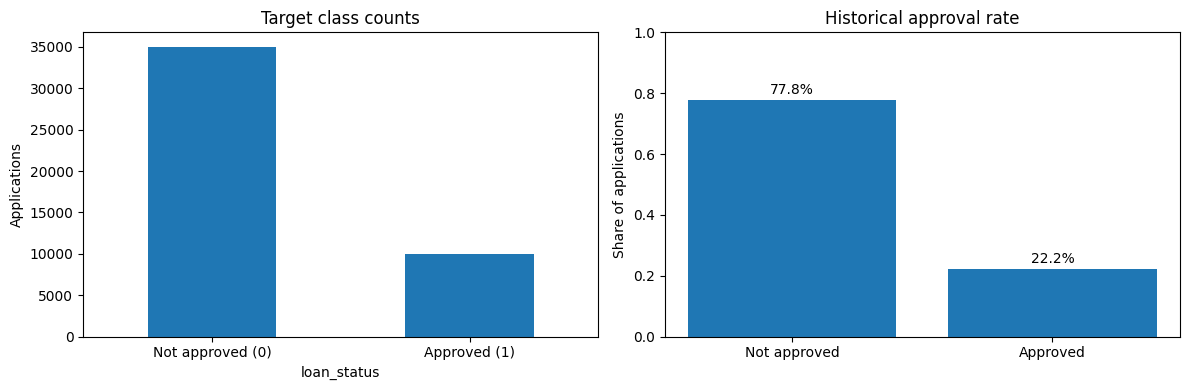

Approval rate: 22.2%


In [ ]:
approval_rate = df[TARGET].mean()
class_counts = df[TARGET].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.rename(index={0: "Not approved (0)", 1: "Approved (1)"}).plot(
    kind="bar", ax=axes[0], title="Target class counts"
)
axes[0].set_ylabel("Applications")
axes[0].tick_params(axis="x", rotation=0)

axes[1].bar(["Not approved", "Approved"], [1-approval_rate, approval_rate])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Share of applications")
axes[1].set_title("Historical approval rate")
for i, v in enumerate([1-approval_rate, approval_rate]):
    axes[1].text(i, v + 0.02, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.show()

print(f"Approval rate: {approval_rate:.1%}")

### Historical Approval Rates based on Categorical Characteristics

Historical approval rates across categories of applicant and loan characteristics were displayed to look for obvious patterns. Differences in approval rates can also indicate differences in other variables such as data collection methods or historical lending practices.

In [ ]:
def approval_rate_by_category(data, column, target=TARGET, min_count=20):
    if column not in data.columns:
        print(f"Skipping {column}: column not found.")
        return
    summary = (
        data.groupby(column, dropna=False)[target]
            .agg(applications="size", approval_rate="mean")
            .query("applications >= @min_count")
            .sort_values("approval_rate", ascending=False)
    )
    display(summary.style.format({"approval_rate": "{:.1%}"}))

for col in ["person_gender", "person_education", "person_home_ownership",
            "loan_intent", "previous_loan_defaults_on_file"]:
    print(f"Approval rate by {col}")
    approval_rate_by_category(df, col)

Approval rate by person_gender


,applications,approval_rate
person_gender,,
female,20159,22.2%
male,24841,22.2%


Approval rate by person_education


,applications,approval_rate
person_education,,
Doctorate,621,22.9%
Bachelor,13399,22.5%
High School,11972,22.3%
Associate,12028,22.0%
Master,6980,21.8%


Approval rate by person_home_ownership


,applications,approval_rate
person_home_ownership,,
OTHER,117,33.3%
RENT,23443,32.4%
MORTGAGE,18489,11.6%
OWN,2951,7.5%


Approval rate by loan_intent


,applications,approval_rate
loan_intent,,
DEBTCONSOLIDATION,7145,30.3%
MEDICAL,8548,27.8%
HOMEIMPROVEMENT,4783,26.3%
PERSONAL,7552,20.1%
EDUCATION,9153,17.0%
VENTURE,7819,14.4%


Approval rate by previous_loan_defaults_on_file


,applications,approval_rate
previous_loan_defaults_on_file,,
No,22142,45.2%
Yes,22858,0.0%


### Numeric Feature Distributions and Approval Comparisons

Histograms were used to look at distributions of selected numerical variables.

Box plots were used to compare their distributions across the two historical outcome classes.

Histograms can show skewness, unusual values, clustering and possible data entry errors. Box plots can summarize the median, interquartile range and potential outliers within each class.

Comparing the distributions across approval outcomes can show relationships that are worth investigating during feature selection and model interpretation steps.

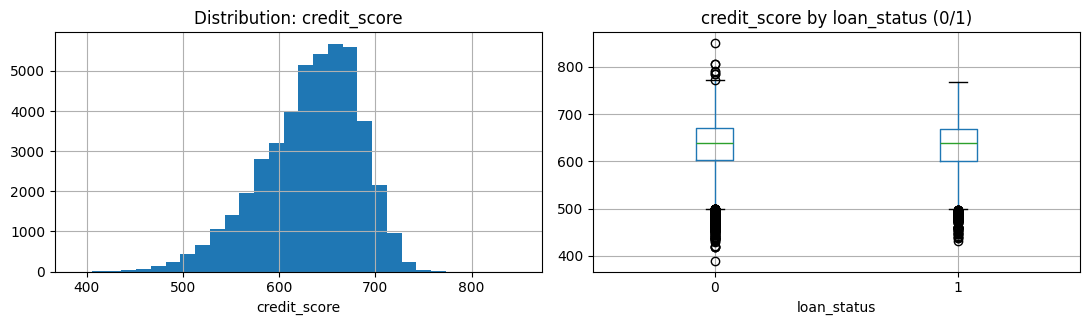

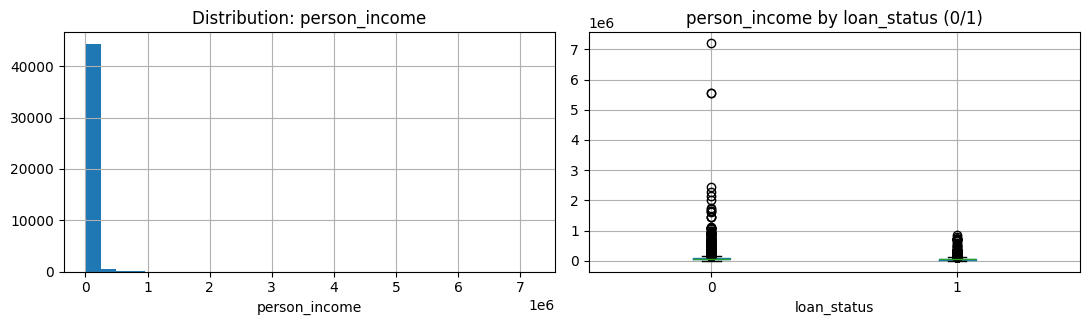

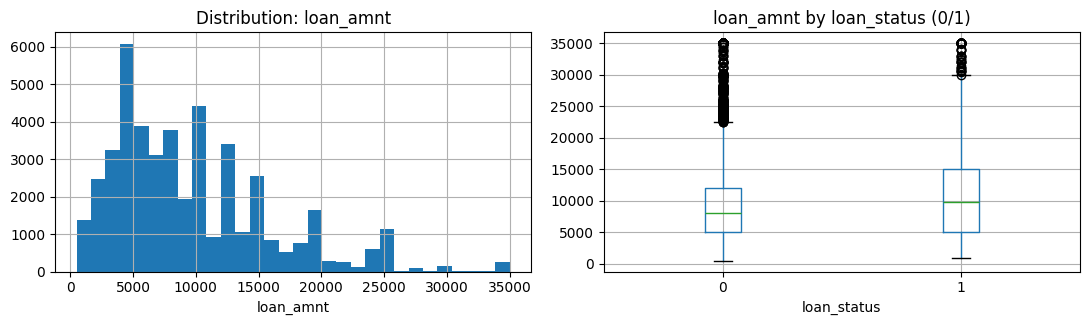

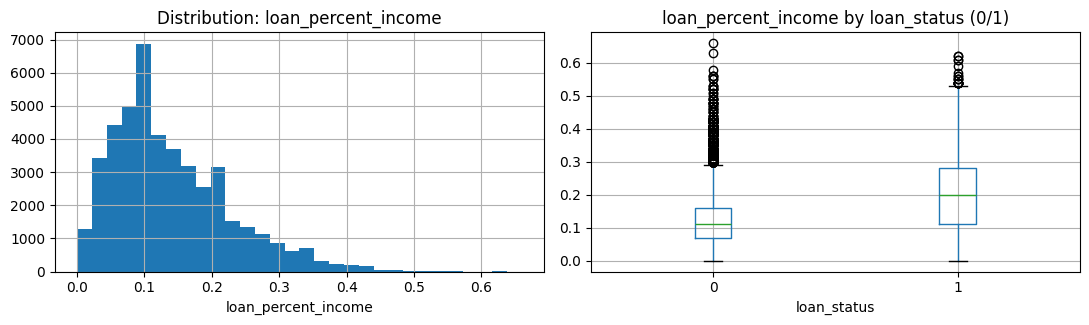

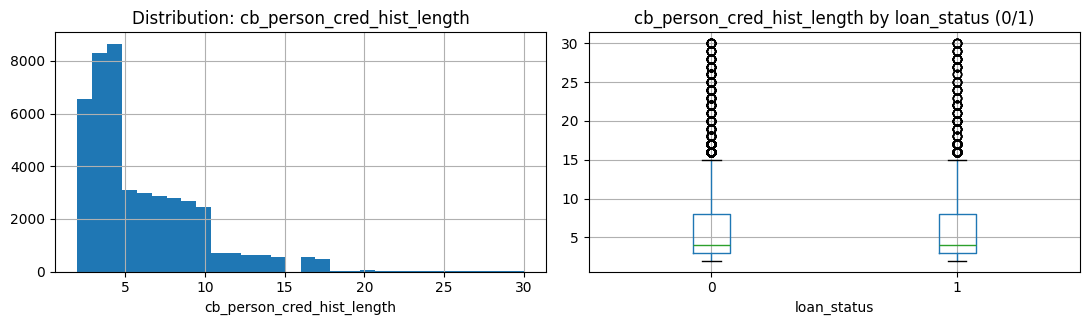

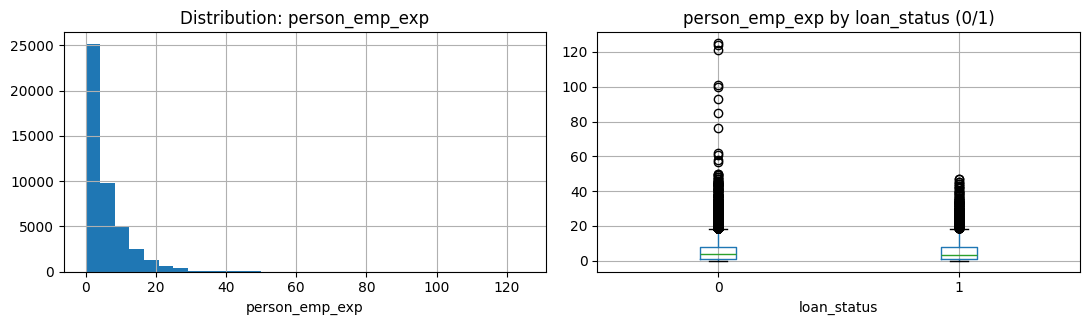

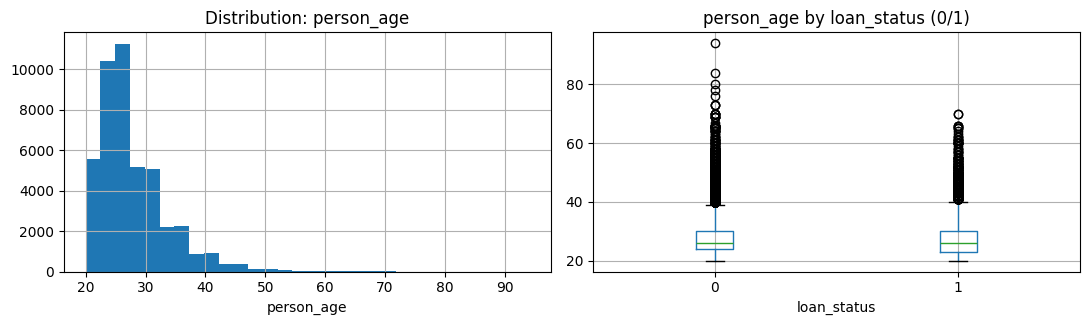

In [ ]:

for col in ["credit_score", "person_income", "loan_amnt", "loan_percent_income",
            "cb_person_cred_hist_length", "person_emp_exp", "person_age"]:
    if col not in df.columns:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    df[col].dropna().hist(bins=30, ax=axes[0])
    axes[0].set_title(f"Distribution: {col}")
    axes[0].set_xlabel(col)
    df.boxplot(column=col, by=TARGET, ax=axes[1])
    axes[1].set_title(f"{col} by loan_status (0/1)")
    axes[1].set_xlabel("loan_status")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

### Feature Engineering for Descriptive Analysis

Selected numeric variables were grouped into sections to make exploratory summaries easier to explain/communicate.

Credit scores were grouped into different tiers, loan burden was grouped by ratio of requested loan amount to income, and interest rates were grouped into different ranges.

These derived variables were used to make summary and visualization of historical approval patterns easier to understand.

The comparisons can help communicate how observed outcomes can vary across ranges of the variables.

Approval by credit_score_tier


,applications,approval_rate
credit_score_tier,,
Near-prime,26806,22.5%
Very good,94,22.3%
Very low / subprime,6901,22.3%
Prime,11196,21.6%


Approval by loan_burden_band


,applications,approval_rate
loan_burden_band,,
>30%,2400,73.1%
20–30%,6808,44.8%
10–20%,16926,17.6%
<=10%,18866,11.8%


Approval by interest_rate_band


,applications,approval_rate
interest_rate_band,,
>16,2235,65.5%
12–16,13087,33.4%
8–12,19648,16.6%
<=8,10030,9.0%


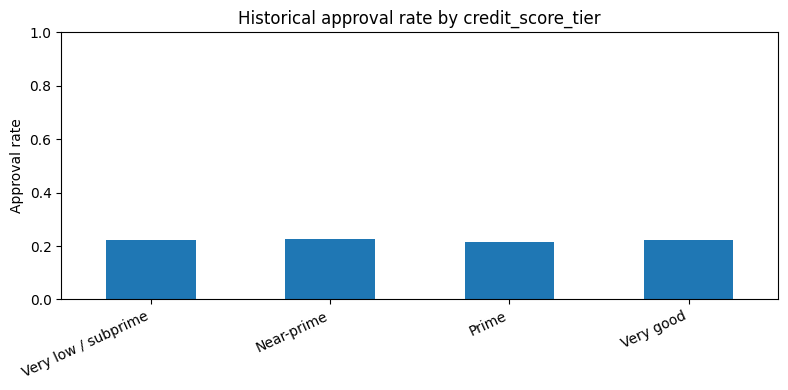

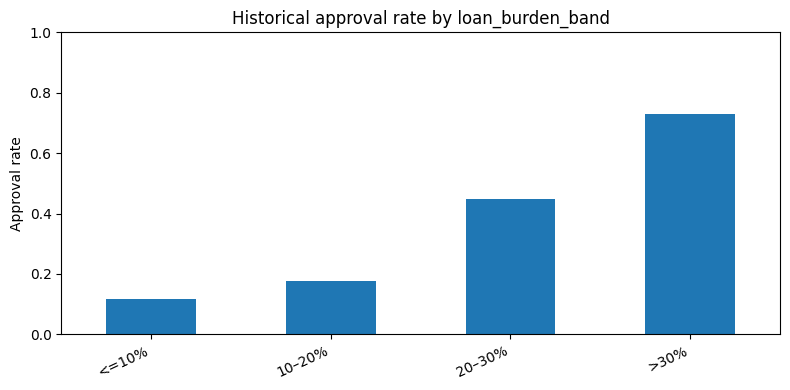

In [ ]:

if "credit_score" in df.columns:
    df["credit_score_tier"] = pd.cut(
        df["credit_score"],
        bins=[-np.inf, 579, 669, 739, 799, np.inf],
        labels=["Very low / subprime", "Near-prime", "Prime", "Very good", "Excellent"]
    )

if "loan_percent_income" in df.columns:
    df["loan_burden_band"] = pd.cut(
        df["loan_percent_income"],
        bins=[-np.inf, 0.10, 0.20, 0.30, np.inf],
        labels=["<=10%", "10–20%", "20–30%", ">30%"]
    )

if "loan_int_rate" in df.columns:
    df["interest_rate_band"] = pd.cut(
        df["loan_int_rate"],
        bins=[-np.inf, 8, 12, 16, np.inf],
        labels=["<=8", "8–12", "12–16", ">16"]
    )

for col in ["credit_score_tier", "loan_burden_band", "interest_rate_band"]:
    if col in df.columns:
        print(f"Approval by {col}")
        approval_rate_by_category(df, col, min_count=20)


for col in ["credit_score_tier", "loan_burden_band"]:
    if col in df.columns:
        rates = df.groupby(col, observed=False)[TARGET].agg(["mean", "count"])
        rates = rates[rates["count"] >= 20]
        if len(rates):
            ax = rates["mean"].plot(kind="bar", figsize=(8, 4), ylim=(0, 1),
                                    title=f"Historical approval rate by {col}")
            ax.set_ylabel("Approval rate")
            ax.set_xlabel("")
            plt.xticks(rotation=25, ha="right")
            plt.tight_layout()
            plt.show()

## Feature Selection and Leakage Concerns

This step took place before models were trained.

The target variable, loan_status, was excluded from the predictors to rpevent the model from using the answer it was suppposed to predict. Audit flags and descriptive bands created for exploratory analysis were also excluded from the primary model.

loan_int_rate was excluded because the recorded interest rate may be assigned or influenced by the lending decision process. If the rate was determined after an application was evaluated, using the rate to predict approval could be considered target leakage.

Age and gender were also excluded from the primary model inputs.

The feature list was printed for review before the dataset was split into separate training and test datasets.

In [ ]:
exclude_from_model = {
    TARGET, "loan_int_rate", "person_age", "person_gender",
    "flag_age_over_100", "flag_experience_over_50",
    "flag_experience_inconsistent_with_age",
    "credit_score_tier", "loan_burden_band", "interest_rate_band"
}

feature_cols = [
    c for c in df.columns
    if c not in exclude_from_model and not c.startswith("flag_")
]

feature_cols = [c for c in feature_cols if c not in
                ["credit_score_tier", "loan_burden_band", "interest_rate_band"]]

X = df[feature_cols].copy()
y = df[TARGET].copy()

print("Primary model features:")
print(feature_cols)
print("\\nTarget definition: 1 = historically approved; 0 = historically not approved.")
print("Potential leakage exclusion: loan_int_rate.")

Primary model features:
['person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file']
\nTarget definition: 1 = historically approved; 0 = historically not approved.
Potential leakage exclusion: loan_int_rate.


### Data Preprocessing and Train-Test Split

The dataset was first split into training and test subsets before preprocessing transformations were performed.

The training set was used to learn imputation values, numeric scaling parameters, categorical encodings, and model parameters. The held-out test set was reserved for evaluating the models' performance on observations that were not used during training.

Numeric features were imputed using the training-set's median and standardized using StandardScaler. Categorical features were imputed using the most frequent training-set category and converted into indicator variables by using one-hot encoding method.

ColumnTransformer was used to apply appropriate transformations to each feature type, and the scikit-learn Pipeline allowed preprocessing and model fitting steps to be performed together.

Stratification was used to keep the proportion of approved and non-approved applicatioins roughly the same in both subsets. A fixed random seed was used to support reproducibility.

In [ ]:
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Training approval rate: {y_train.mean():.1%}")
print(f"Test approval rate: {y_test.mean():.1%}")

Training rows: 36,000
Test rows: 9,000
Training approval rate: 22.2%
Test approval rate: 22.2%


## Model Training and Performance Comparison

Three supervised classification algorithms were trained to predict loan approval outcomes.

Logistic Regression can provide a pretty interpretable baseline and estimate possibility of loan approval by using a logistic function.

Random Forest can combine predictions from multiple random decisioin trees to model nonlinear patterns and interactions between features.

Gradient Boosting can build a sequence of decision trees and have later trees try to improve errors made by earlier ones.

Each of these three models were trained by using the same training set and preprocessing strategy. Predicted approval probabilities were created for the held-out test set and classification metrics were calculated at a probability threshold of 0.50.

These models were compared by using methods such as ROC-AUC, KS statistic, accuracy, precision, recall, F1-score, and Brier scores. These metrics captured different aspects of model performance and should be considered.

In [ ]:
models = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight=None, random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight=None,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

fitted_models = {}
predicted_probabilities = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    prob = pipe.predict_proba(X_test)[:, 1]
    predicted_probabilities[name] = prob
    pred = (prob >= 0.50).astype(int)

    fpr, tpr, _ = roc_curve(y_test, prob)
    ks = float(np.max(tpr - fpr))

    results.append({
        "model": name,
        "ROC_AUC": roc_auc_score(y_test, prob),
        "KS_statistic": ks,
        "Accuracy_at_0.50": accuracy_score(y_test, pred),
        "Precision_at_0.50": precision_score(y_test, pred, zero_division=0),
        "Recall_at_0.50": recall_score(y_test, pred, zero_division=0),
        "F1_at_0.50": f1_score(y_test, pred, zero_division=0),
        "Brier_score": brier_score_loss(y_test, prob)
    })

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
display(results_df.style.format({
    "ROC_AUC": "{:.3f}", "KS_statistic": "{:.3f}",
    "Accuracy_at_0.50": "{:.3f}", "Precision_at_0.50": "{:.3f}",
    "Recall_at_0.50": "{:.3f}", "F1_at_0.50": "{:.3f}",
    "Brier_score": "{:.3f}"
}))

,model,ROC_AUC,KS_statistic,Accuracy_at_0.50,Precision_at_0.50,Recall_at_0.50,F1_at_0.50,Brier_score
1,Random forest,0.954,0.740,0.899,0.858,0.651,0.741,0.069
2,Gradient boosting,0.953,0.734,0.897,0.867,0.636,0.734,0.070
0,Logistic regression,0.936,0.708,0.871,0.736,0.656,0.694,0.084


### ROC Curve Analysis
The ROC curve can be used to evaluate the trade-off between the true positive rate and false positive rate across classification thresholds.

For this project, the true positive rate was the proportion of historically approved applications that were correctly classified as "approved" or 1. The false positive rate was the proportion of historically non-approvated applications that were incorrectly classified as approved.

The area under the ROC curve (a.k.a. ROC-AUC) summarized the model's ability to distinguish between classes. A diagonal reference line was used to represent a chance-level classification performance.

Comparing the curves of the different models can help assess whether one model generally separated the two historical outcome classes between than another class.

### Confusion Matrix and Classification Report

The model with the highest held-out test ROC-AUC was selected for further diagnostic analysis.

Predicted probabilities were converted into binary classifications by using a threshold of 0.50. A confusion matrix was used to compare predicted classes against real historical outcomes. Counts of true negatives, false positives, false negatives, and true positives were compared.

A classification report displayed precision, recall, and F1-score metrics for each class. These metrics helped identify different types of errors the model made and whether performance differed significantly between historically approved and non-approved applications.

The 0.50 threshold was simply used as an initial reference point.

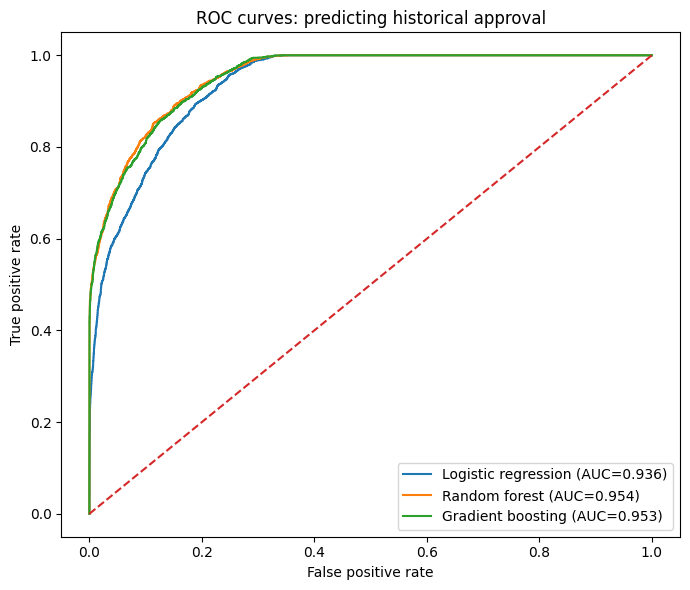

Top model by test ROC-AUC: Random forest
Confusion matrix at threshold 0.50 (rows=actual, columns=predicted):


,Predicted not approved (0),Predicted approved (1)
Actual not approved (0),6785,215
Actual approved (1),697,1303


              precision    recall  f1-score   support

Not approved       0.91      0.97      0.94      7000
    Approved       0.86      0.65      0.74      2000

    accuracy                           0.90      9000
   macro avg       0.88      0.81      0.84      9000
weighted avg       0.90      0.90      0.89      9000



In [ ]:
plt.figure(figsize=(7, 6))
for name, prob in predicted_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves: predicting historical approval")
plt.legend()
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["model"]
best_model = fitted_models[best_model_name]
best_prob = predicted_probabilities[best_model_name]
best_pred_050 = (best_prob >= 0.50).astype(int)

print("Top model by test ROC-AUC:", best_model_name)
print("Confusion matrix at threshold 0.50 (rows=actual, columns=predicted):")
display(pd.DataFrame(
    confusion_matrix(y_test, best_pred_050, labels=[0, 1]),
    index=["Actual not approved (0)", "Actual approved (1)"],
    columns=["Predicted not approved (0)", "Predicted approved (1)"]
))
print(classification_report(y_test, best_pred_050, target_names=["Not approved", "Approved"], zero_division=0))

### Classification Threshold Analysis

A classification model can produce probabilities, but a threshold is needed to transform probabilities into binary predictions.

This section evaluated the model's performance at thresholds ranging from 0.10 to 0.90. For each threshold, the analysis calculated the predicted approval rate, precision, recall, false positive rate, and false negative rate.

Lowering the threshold generally increased the amount of applications classified as approved, and raising it generally decreased that number. Precision and recall can both in different directions.

The threshold chart can show trade-offs between different metrics. Choosing a threshold can depend on different reasons such as error costs, and business constraints.

,threshold,predicted_approval_share,precision,recall,false_positive_rate,false_negative_rate
0,0.10,45.0%,48.9%,99.1%,29.6%,0.9%
1,0.15,41.7%,51.7%,97.2%,25.9%,2.9%
2,0.20,38.1%,55.2%,94.6%,21.9%,5.4%
3,0.25,33.9%,59.6%,91.0%,17.6%,8.9%
4,0.30,29.9%,64.8%,87.0%,13.5%,13.0%
5,0.35,26.0%,70.2%,82.2%,10.0%,17.8%
6,0.40,22.3%,76.3%,76.7%,6.8%,23.3%
7,0.45,19.4%,81.2%,70.8%,4.7%,29.2%
8,0.50,16.9%,85.8%,65.1%,3.1%,34.8%
9,0.55,14.7%,90.2%,59.6%,1.9%,40.5%


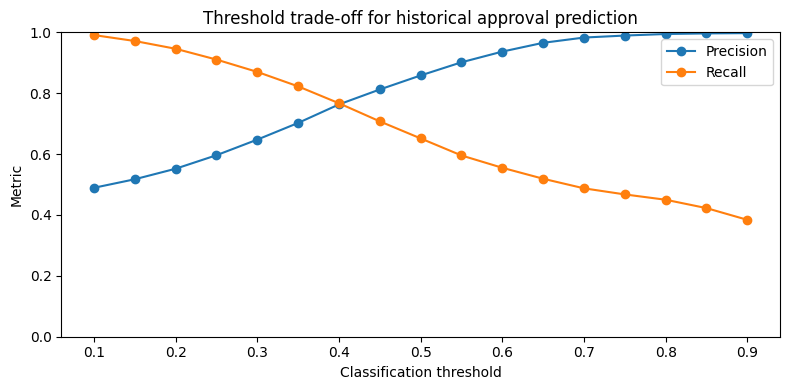

In [ ]:
threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (best_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "predicted_approval_share": pred.mean(),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else np.nan,
        "false_negative_rate": fn / (fn + tp) if (fn + tp) else np.nan
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.style.format({
    "threshold": "{:.2f}", "predicted_approval_share": "{:.1%}",
    "precision": "{:.1%}", "recall": "{:.1%}",
    "false_positive_rate": "{:.1%}", "false_negative_rate": "{:.1%}"
}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
ax.plot(threshold_df["threshold"], threshold_df["recall"], marker="o", label="Recall")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Metric")
ax.set_ylim(0, 1)
ax.set_title("Threshold trade-off for historical approval prediction")
ax.legend()
plt.tight_layout()
plt.show()

### Probability Calibration

Calibration analysis can be used to compare predicted probabilities with observed approval rates. A diagonal reference line was used to represent an example of perfect calibration. Points near this line showed that predicted probabilities were similar to observed historical approval frequencies for corresponding groups.

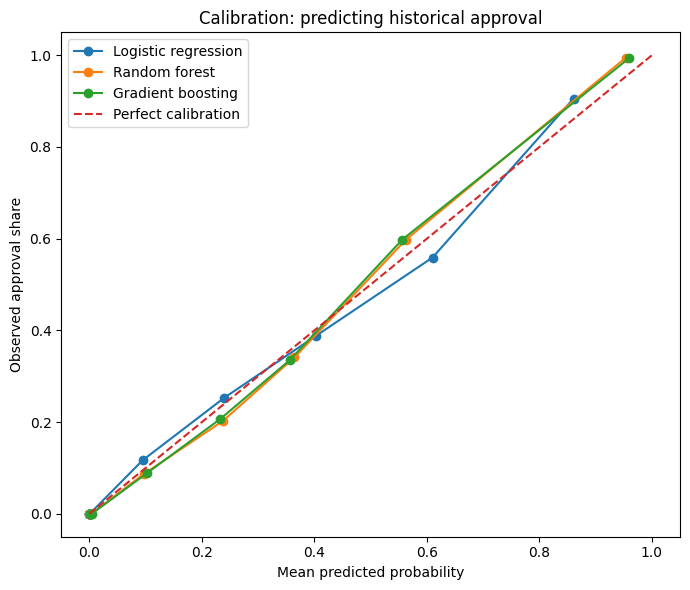

In [ ]:
plt.figure(figsize=(7, 6))
for name, prob in predicted_probabilities.items():
    frac_positive, mean_predicted = calibration_curve(
        y_test, prob, n_bins=10, strategy="quantile"
    )
    plt.plot(mean_predicted, frac_positive, marker="o", label=name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed approval share")
plt.title("Calibration: predicting historical approval")
plt.legend()
plt.tight_layout()
plt.show()

### Logistic Regression Coefficients

Logistic Regression can allow you to examine how transformed predictors were associated with the model's estimated odds of historical loan approval.

The coefficient table displayed each transformed feature, its coefficient, and its odds ratio (exponentiated coefficient). Numeric features were standardized and categorical features were one-hot encoded.

Positive coefficients indicated higher log-odds of historical loan approval rates, and negative coefficients corresponded to lower estimated log-odds.


In [ ]:
logit_pipe = fitted_models.get("Logistic regression")
if logit_pipe is not None:
    fitted_preprocessor = logit_pipe.named_steps["preprocessor"]
    logit = logit_pipe.named_steps["model"]
    try:
        transformed_names = fitted_preprocessor.get_feature_names_out()
        coefficients = logit.coef_[0]
        odds_table = pd.DataFrame({
            "feature": transformed_names,
            "coefficient": coefficients,
            "odds_ratio": np.exp(np.clip(coefficients, -20, 20))
        })
        odds_table["abs_coefficient"] = odds_table["coefficient"].abs()
        display(odds_table.sort_values("abs_coefficient", ascending=False)
                .drop(columns="abs_coefficient").head(20)
                .style.format({"coefficient": "{:.3f}", "odds_ratio": "{:.3f}"}))
    except Exception as e:
        print("Could not retrieve transformed feature names:", e)

,feature,coefficient,odds_ratio
22,cat__previous_loan_defaults_on_file_Yes,-5.225,0.005
21,cat__previous_loan_defaults_on_file_No,2.995,19.984
13,cat__person_home_ownership_OWN,-1.833,0.160
3,num__loan_percent_income,1.134,3.109
20,cat__loan_intent_VENTURE,-0.992,0.371
16,cat__loan_intent_EDUCATION,-0.802,0.449
11,cat__person_home_ownership_MORTGAGE,-0.667,0.513
19,cat__loan_intent_PERSONAL,-0.553,0.575
6,cat__person_education_Associate,-0.477,0.620
7,cat__person_education_Bachelor,-0.470,0.625


### Subgroup Performance Audit

The selected model was evaluated across selected demographic groups by using the held-out test observations. Gender and age were excluded from the primary model inputs but used for this audit.

For each large subgroup, the analysis reported the number of observations, observed historical approval rate in this dataset, predicted approval rate, precision and recall scores.

The goal was to look for possible differences in model behavior.



In [ ]:
audit_cols = [c for c in ["person_gender", "person_age"] if c in df.columns]
audit = df.loc[X_test.index, audit_cols].copy()
audit["actual"] = y_test.loc[X_test.index].values
audit["predicted_probability"] = best_prob
audit["predicted_approval"] = (best_prob >= 0.50).astype(int)

for group_col in ["person_gender", "person_age"]:
    if group_col not in audit.columns:
        continue
    if group_col == "person_age":
        audit["age_band_audit"] = pd.cut(
            pd.to_numeric(audit[group_col], errors="coerce"),
            bins=[-np.inf, 24, 34, 44, 54, 64, np.inf],
            labels=["<=24", "25–34", "35–44", "45–54", "55–64", "65+"]
        )
        col = "age_band_audit"
    else:
        col = group_col

    rows = []
    for group, part in audit.groupby(col, dropna=False, observed=False):
        if len(part) < 30:
            continue
        rows.append({
            "group": str(group),
            "n": len(part),
            "actual_approval_rate": part["actual"].mean(),
            "predicted_approval_rate": part["predicted_approval"].mean(),
            "precision": precision_score(part["actual"], part["predicted_approval"], zero_division=0),
            "recall": recall_score(part["actual"], part["predicted_approval"], zero_division=0)
        })
    print(f"Subgroup audit by {group_col} (groups with at least 30 test cases)")
    if rows:
        display(pd.DataFrame(rows).style.format({
            "actual_approval_rate": "{:.1%}",
            "predicted_approval_rate": "{:.1%}",
            "precision": "{:.1%}", "recall": "{:.1%}"
        }))
    else:
        print("No groups met the minimum sample size.")

Subgroup audit by person_gender (groups with at least 30 test cases)


,group,n,actual_approval_rate,predicted_approval_rate,precision,recall
0,female,3945,21.6%,16.6%,84.8%,64.9%
1,male,5055,22.7%,17.1%,86.6%,65.4%


Subgroup audit by person_age (groups with at least 30 test cases)


,group,n,actual_approval_rate,predicted_approval_rate,precision,recall
0,<=24,3213,23.8%,19.9%,86.2%,71.9%
1,25–34,4740,21.4%,15.5%,84.8%,61.6%
2,35–44,876,21.0%,13.6%,88.2%,57.1%
3,45–54,134,18.7%,9.7%,92.3%,48.0%


### Sensitivity Analysis with Loan Interest Rate

The primary model excluded loan_int_rate.

A sensitivity analysis fit a separate Logistic Regression model that did include the interest rate variable and compared its test ROC-AUC metric with that of the primary Logistic Regression model's.

A change in ROC-AUC can indicate that the interest rate can change the model's ability to classify classes. A huge improvement can suggest that the variable did contain predictive information.

It's unclear if interest rates were assigned after or as part of the approval decision. The sensitivity model might have relied on information that would not be available when a real prediction needs to be made.

In [ ]:
if "loan_int_rate" in df.columns:
    sensitivity_features = [c for c in feature_cols if c != "loan_int_rate"]
    X_sens = df[sensitivity_features + ["loan_int_rate"]].copy()
    y_sens = df[TARGET].copy()

    Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
        X_sens, y_sens, test_size=0.20, random_state=RANDOM_STATE, stratify=y_sens
    )

    num_s = X_sens.select_dtypes(include=["number", "bool"]).columns.tolist()
    cat_s = [c for c in X_sens.columns if c not in num_s]
    prep_s = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num_s),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_s)
    ])

    sens_pipe = Pipeline([
        ("preprocessor", prep_s),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ])
    sens_pipe.fit(Xtr_s, ytr_s)
    p_sens = sens_pipe.predict_proba(Xte_s)[:, 1]

    print(f"Primary logistic regression AUC (without interest rate): "
          f"{roc_auc_score(y_test, predicted_probabilities['Logistic regression']):.3f}")
    print(f"Sensitivity logistic regression AUC (with interest rate): "
          f"{roc_auc_score(yte_s, p_sens):.3f}")
    print("Interpret the difference only after confirming whether interest rate is available at decision time.")
else:
    print("loan_int_rate not present; skipping sensitivity analysis.")

Primary logistic regression AUC (without interest rate): 0.936
Sensitivity logistic regression AUC (with interest rate): 0.956
Interpret the difference only after confirming whether interest rate is available at decision time.


In [ ]:
print(f"Dataset rows after cleaning: {len(df):,}")
print(f"Historical approval rate: {df[TARGET].mean():.1%}")
print(f"Best model by test ROC-AUC: {best_model_name}")
print(f"Best model's test ROC-AUC: {roc_auc_score(y_test, best_prob):.3f}")
print(f"Best model's test KS statistic: {np.max(roc_curve(y_test, best_prob)[1] - roc_curve(y_test, best_prob)[0]):.3f}")


Dataset rows after cleaning: 45,000
Historical approval rate: 22.2%
Best model by test ROC-AUC: Random forest
Best model's test ROC-AUC: 0.954
Best model's test KS statistic: 0.740


## Conclusion & Findings

### Project Summary

This project studied historical loan approval outcomes by using exploratory data analysis and three supervised classification algorithms: Logistic Regression, Random Forest, and Gradient Boosting.

The analysis also included data quality assessment, feature selection, preprocessing, model comparison, threshold sensitivity, probability calibration, coefficient interpretation, and a subgroup performance audit.

### Key Findings

#### Historical Approval Patterns

The overall percentage of applications that were approved for loans was 22.2%. Historical approval rates were roughly the same among applicants in higher and lower credit-score tiers. Approval rates were significantly higher for applicants whose loan amount was a higher percentage of their income, which was surprising. Loan approval rates were pretty similar across genders and applicants with different education levels. Approval rates were higher for applicants who rented homes compared to those who owned them. Loan intent seemed to matter. Those who requested loans for debt consolidation and medical reasons had higher approval rates than those who requested them for education and venture reasons. The approval rates for those who didn’t previously have a loan default was around 45.2% but those who did have one had around a 0% approval rate. These were simply descriptive relationships in the dataset.

### Model Performance

Three classification models (Logistic Regression, Random Forest, and Gradient Boosting) were evaluated using test data. The model with the highest test ROC-AUC was Random Forest and it achieved a metric of 0.954. At the 0.50 classification threshold, it achieved a weighted precision score of 0.90, a weighted recall score of 0.90 and a f1-score of 0.89. These results summarized prediction of historical approval outcomes, not future loan repayment.

### Classification trade-offs
Threshold analysis showed that changing the classification cutoff affected the predicted approval share, precision and recall metrics. When the threshold increased from 0.35 to 0.45, the precision increased and the recall decreased. When the threshold was 0.40, the model had roughly the same precision and recall scores. This analysis illustrated the trade-off between identifying more approved applications and making few incorrect approval predictions.

### Probability calibration

The calibration plot compared predicted probabilities with observed historical approval rates. The three models' curves appeared to be around the same distance from the perfect calibration reference line.